In [ ]:
# Install KaggleHub
!pip -q install kagglehub

import kagglehub
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split
import matplotlib.pyplot as plt

# Download Cats vs Dogs dataset
path = kagglehub.dataset_download("tongpython/cat-and-dog")

print("Dataset downloaded to:", path)
print("Files:", os.listdir(path))

# Preprocessing
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

# Load dataset
dataset = datasets.ImageFolder(path, transform=transform)

# Split dataset
train_size = int(0.8 * len(dataset))
test_size = len(dataset) - train_size

train_data, test_data = random_split(
    dataset,
    [train_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
test_loader = DataLoader(test_data, batch_size=32, shuffle=False)

print("Classes:", dataset.classes)
print("Training images:", len(train_data))
print("Testing images:", len(test_data))

Using Colab cache for faster access to the 'cat-and-dog' dataset.
Dataset downloaded to: /kaggle/input/cat-and-dog
Files: ['test_set', 'training_set']
Classes: ['test_set', 'training_set']
Training images: 8022
Testing images: 2006


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Load pretrained ResNet18
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Freeze pretrained layers
for param in model.parameters():
    param.requires_grad = False

# Replace final layer for Cats and Dogs
model.fc = nn.Linear(model.fc.in_features, 2)

model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)

print("Model ready!")

Device: cpu
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 109MB/s]


Model ready!


In [ ]:
epochs = 5

train_losses = []
train_accuracies = []

for epoch in range(epochs):

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = 100 * correct / total

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Loss: {epoch_loss:.4f} "
        f"Accuracy: {epoch_accuracy:.2f}%"
    )

Epoch [1/5] Loss: 0.5382 Accuracy: 79.14%
Epoch [2/5] Loss: 0.5145 Accuracy: 79.73%
Epoch [3/5] Loss: 0.5133 Accuracy: 79.74%
Epoch [4/5] Loss: 0.5092 Accuracy: 79.96%
Epoch [5/5] Loss: 0.5101 Accuracy: 79.79%


In [ ]:
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print("Test Accuracy:", round(accuracy, 2), "%")


Test Accuracy: 79.21 %


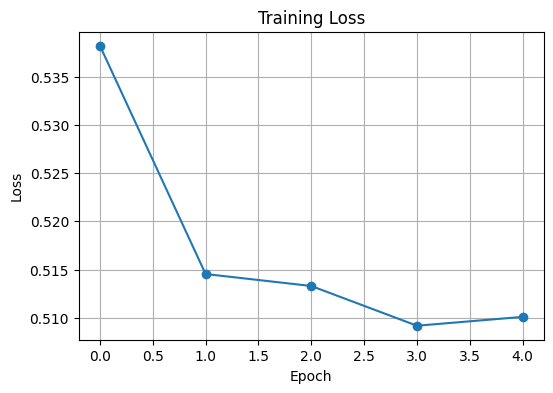

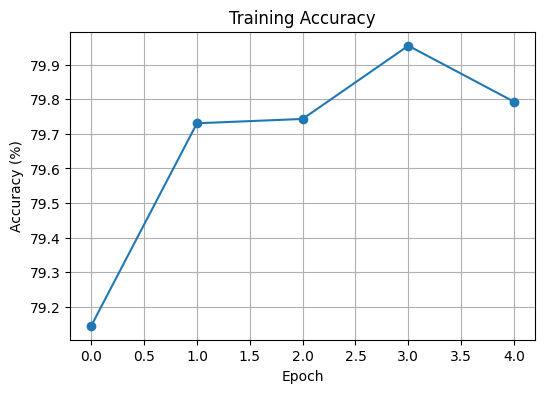

In [ ]:
# Loss graph
plt.figure(figsize=(6,4))

plt.plot(train_losses, marker='o')

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")

plt.grid()
plt.show()


# Accuracy graph
plt.figure(figsize=(6,4))

plt.plot(train_accuracies, marker='o')

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training Accuracy")

plt.grid()
plt.show()

In [ ]:
model.eval()

images, labels = next(iter(test_loader))

images_gpu = images.to(device)

with torch.no_grad():
    outputs = model(images_gpu)
    _, predictions = torch.max(outputs, 1)

plt.figure(figsize=(10,6))

for i in range(8):

    img = images[i].permute(1, 2, 0)

    # Unnormalize
    img = img * torch.tensor([0.229, 0.224, 0.225]) + \
          torch.tensor([0.485, 0.456, 0.406])

    img = torch.clamp(img, 0, 1)

    plt.subplot(2,4,i+1)
    plt.imshow(img)

    plt.title(
        "Actual: " + dataset.classes[labels[i]] +
        "\nPredicted: " + dataset.classes[predictions[i]]
    )

    plt.axis("off")

plt.tight_layout()
plt.show()


print("\nOBSERVATION:")
print("ResNet18 was successfully fine-tuned for Cats vs Dogs classification.")
print("The pretrained CNN features helped the model learn the classification task efficiently.")

print("\nCONCLUSION:")
print("Transfer learning using ResNet18 is effective for image classification.")
print("The model successfully classified images into Cat and Dog classes.")